# 29 · LexCube: slice a real fire cube in the browser

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** render the upstream LexCube widget; navigate time–latitude–longitude; reconcile a visual slice with exact Python values.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=29_seasfire_lexcube.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Load the browser widget

This is **LexCube 2.0.1**, not the deck.gl lab. Its Python backend runs in Pyodide and communicates
with its Jupyter widget frontend. The first setup downloads compatible packages and can take a minute.
Keep this tab open until the cell finishes. WebGL2 is required for the interactive view.

The helper installs the hash-pinned upstream wheel and disables its optional native process-memory diagnostic
inside the browser. Tile compression, values and rendering remain upstream code. LexCube retains
**GPL-3.0-or-later**; [source and adaptation notes](https://jltobias.github.io/JupyterLite-zarr-sql-views/vendor/lexcube/README.md)
are distributed with the site. Native Jupyter uses the regular installed package.
The Jupyter Book supplies a static reference map; use **Run in JupyterLite** for live interaction.

In [2]:
from lexcube_lite import setup_lexcube, cube_sliders
lexcube=await setup_lexcube()
from seasfire import load_seasfire, data_array, raster
d=load_seasfire('ghana')
a=data_array(d,'gwis_ba')
print('LexCube',lexcube.__version__,'| dimensions:',a.dims,'| shape:',a.shape)
print('Data:',a.attrs['source'],'|',a.attrs['units'])

LexCube 2.0.1 | dimensions: ('time', 'latitude', 'longitude') | shape: (184, 16, 16)
Data: https://doi.org/10.5281/zenodo.13834057 | hectares (ha)


## 2. Read the axes before rotating

The array order is **time, latitude, longitude**. LexCube displays time on Z, latitude on Y and longitude on X.
Time is not altitude, and voxels are not three-dimensional vegetation or smoke measurements.
The fixed color limits encode hectares per cell per period. Missing cells stay missing.

Drag to rotate, use the controls to switch between surface and voxel views, and adjust the clipping sliders.
Left-click the displayed data to explore a time series. The time axis advances by index, including shorter
year-end bins. Float32 voxel transfers are requested to avoid extra float16 rounding.

**Read the voxel-mode label:** volume controls can show raw values or seasonal anomalies and can filter
by a threshold or quantile. Switch the target to **values** for a raw-hectare comparison. LexCube's own
anomaly display is not the training-only baseline from lesson 28. A thresholded voxel view does not show
every value in the selection; the summary button below always reports the full selected array.

In [3]:
w=lexcube.Cube3DWidget(a,cmap='inferno',vmin=0,vmax=float(a.max()),
                         widget_size=(10,7),force_float32_for_voxel_mode=True)
w.xlim=(0,16);w.ylim=(0,16);w.zlim=(0,len(a.time))
display(w)
display(cube_sliders(w,a))

Xarray input object does not have chunks. You can re-open with 'chunks={}' to enable dask for caching and progress reporting functionality - but may be overall slower for small data sets.


Cube3DWidget(api_metadata={'/api': {'status': 'ok', 'api_version': 6}, '/api/datasets': [{'id': 'default', 'sh…

## 3. Make the visual selection auditable

The initial view shows all of 2018–2021. Limits use **start-inclusive, stop-exclusive indices**.
The button reads the current widget limits after your edits, reports exact values from the selected array,
and states the full denominator. It does not sum colors or infer values from a screenshot.
Click it after changing sliders; keyboard users can tab to and edit the range controls.
For 2018 alone, set time limits to `(0,46)`. Switching surface/volume modes can reset the clip;
read the displayed bounds and refresh the summary after changing mode.

In [4]:
import ipywidgets as widgets
result=widgets.Output()
button=widgets.Button(description='Summarize selection',layout=widgets.Layout(width='200px'))
def summarize(_=None):
    with result:
        result.clear_output(wait=True)
        selected=w.get_current_cube_selection()
        values=selected.values
        print('Selection shape:',values.shape,'| finite cells:',int(np.isfinite(values).sum()),'/',values.size)
        if values.size:
            print('First / last starts:',str(selected.time.values[0])[:10],str(selected.time.values[-1])[:10])
            print('Sum of reported burned area:',round(float(np.nansum(values)),2),'ha across the selected cell-periods')
            print('This sum is not unique burned land area; repeated burning can be counted across periods.')
button.on_click(summarize)
display(button,result)
summarize()

Button(description='Summarize selection', layout=Layout(width='200px'), style=ButtonStyle())

Output()

## 4. Keep a static view with the same units

A 2D map is easier to print, compare and describe in text. Below is the highest-total period in the
2018 reference year, with the same color range as the interactive cube. It remains readable in the Book
without a widget connection. Record the dates and limits with any screenshot.

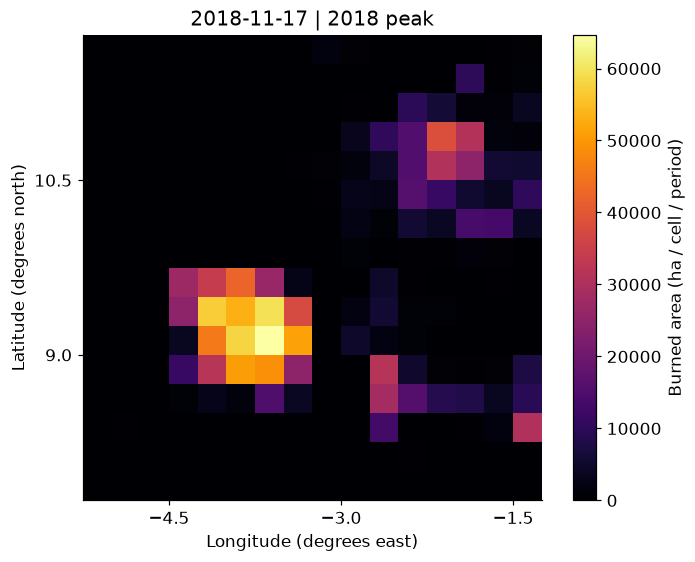

Full cube: (184, 16, 16) | 2018 reference: (46, 16, 16)


In [5]:
peak=int(np.argmax(a.values[:46].sum(axis=(1,2))))
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
image=raster(ax,d,a.values[peak],str(a.time.values[peak])[:10]+' | 2018 peak',vmax=float(a.max()))
fig.colorbar(image,ax=ax,label='Burned area (ha / cell / period)')
plt.show()
print('Full cube:',a.shape,'| 2018 reference:',a.values[:46].shape)

## Try it yourself

Clip a quarter-year and a smaller spatial window. Use the summary button, then change a bound and explain why the denominator changed.

## Check your reasoning

Clipping selects original cell-periods. It does not increase spatial resolution or turn historical values into predictions. Report start/stop indices and dates.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [SeasFire Cube v0.4, Alonso et al. (2024)](https://doi.org/10.5281/zenodo.13834057), CC-BY-4.0. Spatial subsets and browser repackaging by this course; no spatial resampling.
- [Karasante, Alonso, Prapas, Ahuja, Carvalhais & Papoutsis (2025), SeasFire cube — a multivariate dataset for global wildfire modeling](https://doi.org/10.1038/s41597-025-04546-3), Scientific Data 12, 368.
- [ESA Open Science Catalog / EarthCODE](https://opensciencedata.esa.int/products/seasfire-cube/item), public SeasFire v0.4 mirror. Inputs used: GWIS burned area, ECMWF/Copernicus ERA5, NASA MODIS MOD13C1 v6 NDVI, and SeasFire derived VPD/cell area.
- [Exact source objects, SHA256 checksums, extraction windows and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/seasfire-provenance.json).
- [Söchting, Scheuermann, Montero & Mahecha (2025), Interactive Earth system data cube visualization in Jupyter notebooks](https://doi.org/10.1080/20964471.2025.2471646), Big Earth Data, 1–15. [LexCube 2.0.1](https://github.com/msoechting/lexcube), Maximilian Söchting and contributors, GPL-3.0-or-later.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 29_seasfire_lexcube')

LESSON COMPLETE: 29_seasfire_lexcube
